# JobGuard AI - Milestone 8: Final Locked Model Evaluation

**Goal:** compare the four selected models on the **held-out test set**, then choose the model that will power the JobGuard web application.

| Data | Role |
|---|---|
| `train.csv` (internal 80/20 split) | model training and **validation-based selection** (Milestones 5-7, and the Logistic Regression correction below) |
| `test.csv` | **final, common, one-time evaluation** of all four locked models |

**Plan**
1. Verify that every artifact exists and the data is intact
2. **Correct the Logistic Regression protocol** (re-select its configuration from validation only)
3. **Lock** all four configurations, and declare the final selection rule, *before* `test.csv` is opened
4. Load `test.csv`, evaluate all four models on exactly the same rows
5. Compare, choose the final model, save everything for the presentation

> **Methodology caveat (kept for the project report).** In Milestone 4, Logistic Regression was evaluated on `test.csv` before the cleaner validation protocol was adopted. All later models (Naive Bayes, XGBoost, DistilBERT) used validation-only selection. To make the final Logistic Regression independent of that early look, Section 2 re-selects its configuration using the validation split only and retrains it. The holdout was nevertheless *inspected* once during that early baseline experiment, and this should be stated honestly in the report.

## 1. Verify artifacts and data

First, setup: the notebook finds the project root whether the kernel starts in the project folder or in `notebooks/`. We also record **fingerprints (MD5 hashes)** of `train.csv` and `test.csv`, and check them again at the end to prove neither file was modified.

In [1]:
import hashlib
import json
import sys
import time
from pathlib import Path

# IMPORTANT (macOS): import xgboost BEFORE torch. If torch is imported first, loading the saved XGBoost
# pipeline crashes the Python process (the two libraries clash over OpenMP). xgboost is also needed here
# so that joblib can load the saved XGBoost pipeline.
import xgboost

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from transformers import AutoModelForSequenceClassification, AutoTokenizer


def find_project_root():
    here = Path.cwd().resolve()
    for folder in [here, here.parent]:
        if (folder / "data").is_dir() and (folder / "src").is_dir():
            return folder
    raise FileNotFoundError(f"Could not find the project root from {here} (it contains data/ and src/).")


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation import calculate_metrics, plot_confusion_matrix

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
for folder in [METRICS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

TRAIN_PATH = PROCESSED_DIR / "train.csv"
TEST_PATH = PROCESSED_DIR / "test.csv"
LR_PATH = MODELS_DIR / "logistic_regression_pipeline.joblib"
NB_PATH = MODELS_DIR / "naive_bayes_pipeline.joblib"
XGB_PATH = MODELS_DIR / "xgboost_pipeline.joblib"
DISTILBERT_DIR = MODELS_DIR / "distilbert"

# The same TF-IDF settings as Milestones 4-6
tfidf_settings = dict(lowercase=True, stop_words="english", ngram_range=(1, 2), min_df=2, max_features=20000)


def file_fingerprint(path):
    return hashlib.md5(Path(path).read_bytes()).hexdigest()


data_fingerprints_at_start = {"train.csv": file_fingerprint(TRAIN_PATH), "test.csv": file_fingerprint(TEST_PATH)}

print("Project root:", PROJECT_ROOT)
print("torch", torch.__version__, "| transformers", transformers.__version__)
print("Data fingerprints recorded:", data_fingerprints_at_start)

Project root: /Users/aphranie/JobGuard AI
torch 2.14.1 | transformers 5.20.2
Data fingerprints recorded: {'train.csv': '0a5b5a32b8d08433aa9858ac2ec5eb71', 'test.csv': '980610d447225de4f8ef37c819b2fc45'}


In [2]:
# --- All artifacts must exist ---
artifact_paths = {
    "train.csv": TRAIN_PATH,
    "test.csv": TEST_PATH,
    "Logistic Regression pipeline": LR_PATH,
    "Naive Bayes pipeline": NB_PATH,
    "XGBoost pipeline": XGB_PATH,
    "DistilBERT folder": DISTILBERT_DIR,
}
for name, path in artifact_paths.items():
    print(f"{name:30s} {'FOUND  ' if path.exists() else 'MISSING'} {path.relative_to(PROJECT_ROOT)}")
    assert path.exists(), f"{name} is missing: {path}"

# --- The DistilBERT folder must contain the model weights (we never recreate or download the trained model) ---
required_distilbert_files = ["config.json", "model.safetensors", "tokenizer.json", "tokenizer_config.json"]
for file_name in required_distilbert_files:
    present = (DISTILBERT_DIR / file_name).exists()
    print(f"  models/distilbert/{file_name:22s} {'FOUND' if present else 'MISSING'}")
if not (DISTILBERT_DIR / "model.safetensors").exists():
    raise FileNotFoundError("models/distilbert/model.safetensors is missing. STOP: the trained DistilBERT model must be "
                            "copied back from Colab; it is not recreated here.")
assert all((DISTILBERT_DIR / name).exists() for name in required_distilbert_files)
print("PASS: all artifacts exist")

train.csv                      FOUND   data/processed/train.csv
test.csv                       FOUND   data/processed/test.csv
Logistic Regression pipeline   FOUND   models/logistic_regression_pipeline.joblib
Naive Bayes pipeline           FOUND   models/naive_bayes_pipeline.joblib
XGBoost pipeline               FOUND   models/xgboost_pipeline.joblib
DistilBERT folder              FOUND   models/distilbert
  models/distilbert/config.json            FOUND
  models/distilbert/model.safetensors      FOUND
  models/distilbert/tokenizer.json         FOUND
  models/distilbert/tokenizer_config.json  FOUND
PASS: all artifacts exist


In [3]:
# --- Integrity checks on the processed data (checks only; nothing here is used to train or tune anything) ---
def check_processed_data():
    train_check = pd.read_csv(TRAIN_PATH, usecols=["combined_text", "fraudulent"])
    test_check = pd.read_csv(TEST_PATH, usecols=["combined_text", "fraudulent"])
    return {
        "train rows": len(train_check),
        "test rows": len(test_check),
        "train/test combined_text overlap": len(set(train_check["combined_text"]) & set(test_check["combined_text"])),
        "target values (train)": sorted(train_check["fraudulent"].unique().tolist()),
        "target values (test)": sorted(test_check["fraudulent"].unique().tolist()),
        "missing combined_text (train)": int(train_check["combined_text"].isna().sum()),
        "missing combined_text (test)": int(test_check["combined_text"].isna().sum()),
    }


data_checks = check_processed_data()     # the two frames are discarded when the function returns
for key, value in data_checks.items():
    print(f"{key:36s} {value}")

assert data_checks["test rows"] == 3214
assert data_checks["train/test combined_text overlap"] == 0
assert data_checks["target values (train)"] == [0, 1] and data_checks["target values (test)"] == [0, 1]
assert data_checks["missing combined_text (train)"] == 0 and data_checks["missing combined_text (test)"] == 0
print()
print("PASS: test.csv has 3,214 rows; train/test text overlap is 0; target is only 0 and 1; no missing combined_text")

train rows                           12852
test rows                            3214
train/test combined_text overlap     0
target values (train)                [0, 1]
target values (test)                 [0, 1]
missing combined_text (train)        0
missing combined_text (test)         0

PASS: test.csv has 3,214 rows; train/test text overlap is 0; target is only 0 and 1; no missing combined_text


## 2. Logistic Regression protocol cleanup (validation only; `test.csv` is NOT used)

We repeat the Milestone 5-7 procedure for Logistic Regression:

1. Recreate the **same internal split** of `train.csv` (`test_size=0.20`, `random_state=42`, stratified).
2. Fit TF-IDF on the internal **model-training subset only**.
3. Compare **standard** and **`class_weight="balanced"`** Logistic Regression on the **validation subset**.
4. Select by **fraud F1** (the primary summary), reading precision and recall alongside it.
5. Retrain the selected configuration as a full pipeline on **all of `train.csv`** and overwrite `models/logistic_regression_pipeline.joblib`.

In [4]:
train = pd.read_csv(TRAIN_PATH)
X_all = train["combined_text"]
y_all = train["fraudulent"]

(X_model_train, X_validation,
 y_model_train, y_validation) = train_test_split(
    X_all, y_all,
    test_size=0.20,
    random_state=42,
    stratify=y_all,
)

print(f"Model-training rows: {len(X_model_train):,} (fraud {int(y_model_train.sum())}) | "
      f"Validation rows: {len(X_validation):,} (fraud {int(y_validation.sum())})")
assert len(set(X_model_train) & set(X_validation)) == 0

tfidf = TfidfVectorizer(**tfidf_settings)
X_model_train_tfidf = tfidf.fit_transform(X_model_train)    # vocabulary learned from the model-training subset only
X_validation_tfidf = tfidf.transform(X_validation)          # validation text is only transformed
print("Vocabulary size:", len(tfidf.get_feature_names_out()), "| model-training matrix:", X_model_train_tfidf.shape)

Model-training rows: 10,281 (fraud 459) | Validation rows: 2,571 (fraud 115)


Vocabulary size: 20000 | model-training matrix: (10281, 20000)


In [5]:
lr_candidates = {
    "Logistic Regression (Standard)": None,
    "Logistic Regression (Balanced)": "balanced",
}

lr_rows = []
for name, class_weight in lr_candidates.items():
    model = LogisticRegression(max_iter=1000, random_state=42, class_weight=class_weight)
    model.fit(X_model_train_tfidf, y_model_train)
    predictions = model.predict(X_validation_tfidf)
    lr_rows.append({"Model": name, "class_weight": str(class_weight), **calculate_metrics(y_validation, predictions)})

lr_validation = pd.DataFrame(lr_rows)
lr_validation[["Model", "Accuracy", "Fraud Precision", "Fraud Recall", "Fraud F1",
               "False Positives", "False Negatives"]].round(4)

,Model,Accuracy,Fraud Precision,Fraud Recall,Fraud F1,False Positives,False Negatives
0,Logistic Regression (Standard),0.9669,1.0000,0.2609,0.4138,0,85
1,Logistic Regression (Balanced),0.9701,0.6118,0.9043,0.7298,66,11


In [6]:
# Select by fraud F1 (primary summary metric); precision and recall are printed so the balance can be read too
best_lr_row = lr_validation.loc[lr_validation["Fraud F1"].idxmax()]
selected_lr_name = best_lr_row["Model"]
selected_lr_class_weight = None if best_lr_row["class_weight"] == "None" else best_lr_row["class_weight"]

for _, row in lr_validation.iterrows():
    print(f"{row['Model']:32s} precision {row['Fraud Precision']:.3f} | recall {row['Fraud Recall']:.3f} | "
          f"F1 {row['Fraud F1']:.3f} | missed scams {int(row['False Negatives'])} | false alarms {int(row['False Positives'])}")
print()
print("Selected Logistic Regression configuration (validation only):", selected_lr_name,
      "| class_weight =", selected_lr_class_weight)

# Sanity: the balanced result must match what Milestones 5 and 6 saved for this same split
saved_validation = pd.read_csv(METRICS_DIR / "model_validation_comparison.csv")
saved_balanced = saved_validation[saved_validation["Model"].str.startswith("Logistic")].iloc[0]
recomputed_balanced = lr_validation[lr_validation["Model"] == "Logistic Regression (Balanced)"].iloc[0]
metric_names = ["Accuracy", "Fraud Precision", "Fraud Recall", "Fraud F1"]
assert np.allclose([recomputed_balanced[m] for m in metric_names], [saved_balanced[m] for m in metric_names])
print("PASS: the recomputed balanced result matches the saved Milestone 5/6 validation result (same split)")

Logistic Regression (Standard)   precision 1.000 | recall 0.261 | F1 0.414 | missed scams 85 | false alarms 0
Logistic Regression (Balanced)   precision 0.612 | recall 0.904 | F1 0.730 | missed scams 11 | false alarms 66

Selected Logistic Regression configuration (validation only): Logistic Regression (Balanced) | class_weight = balanced
PASS: the recomputed balanced result matches the saved Milestone 5/6 validation result (same split)


**Reading the result.** Standard Logistic Regression is extremely cautious: precision 1.000, but recall only 0.261, so it misses 85 of the 115 validation scams (F1 0.414). The class-balanced version trades some precision (false alarms: 66) for much higher recall (0.904, only 11 missed) and a far higher F1 (0.730). By the validation-only rule the **balanced** configuration is selected.

**Effect of the correction.** The newly trained pipeline is numerically identical to the one saved in Milestone 4, so the correction **confirmed** the earlier configuration rather than changing it. The correction still matters methodologically: the choice is now justified from validation data alone, independent of the early test-set look. The file `models/logistic_regression_pipeline.joblib` was overwritten with this version.

In [7]:
# Retrain the selected configuration as a full Pipeline on ALL of train.csv (no test data)
old_pipeline = joblib.load(LR_PATH)     # the Milestone 4 version, loaded only to document what changes (if anything)
old_class_weight = old_pipeline.named_steps["logistic_regression"].class_weight

lr_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(**tfidf_settings)),
    ("logistic_regression", LogisticRegression(max_iter=1000, random_state=42, class_weight=selected_lr_class_weight)),
])
lr_pipeline.fit(X_all, y_all)

same_vocabulary = (list(old_pipeline.named_steps["tfidf"].get_feature_names_out())
                   == list(lr_pipeline.named_steps["tfidf"].get_feature_names_out()))
same_coefficients = bool(same_vocabulary and np.allclose(old_pipeline.named_steps["logistic_regression"].coef_,
                                                         lr_pipeline.named_steps["logistic_regression"].coef_))
print("Previously saved pipeline used class_weight =", old_class_weight, "| newly selected:", selected_lr_class_weight)
print("New pipeline is numerically identical to the previously saved one:", same_coefficients)

joblib.dump(lr_pipeline, LR_PATH)
print("Overwrote:", LR_PATH.relative_to(PROJECT_ROOT), f"({LR_PATH.stat().st_size / 1_000_000:.1f} MB), trained on {len(X_all):,} rows")

# Record the validation selection for the project report
lr_selection_record = lr_validation.assign(Selected=lambda df: df["Model"] == selected_lr_name,
                                           Note="validation-only selection; test.csv not used")
lr_selection_record.to_csv(METRICS_DIR / "logistic_regression_validation_selection.csv", index=False)
print("Saved results/metrics/logistic_regression_validation_selection.csv")

Previously saved pipeline used class_weight = balanced | newly selected: balanced
New pipeline is numerically identical to the previously saved one: True
Overwrote: models/logistic_regression_pipeline.joblib (1.0 MB), trained on 12,852 rows
Saved results/metrics/logistic_regression_validation_selection.csv


## 3. Lock the four models

From this point on, **nothing may change based on test results**: no threshold, class weighting, `alpha`, XGBoost setting, TF-IDF setting, tokenization setting or model configuration.

The cell below reads each configuration **from the saved model files** (so the lock describes what is really on disk), checks them against the agreed configuration, and records a **fingerprint of every model file**. After the test evaluation we verify that none of these files or settings changed.

**Decision rule for every model:** the model's default prediction (the more probable of the two classes, i.e. a 0.5 probability threshold). No threshold is tuned.

**Final-selection rule (declared now, before `test.csv` is opened):**
1. Rank the four models by **test fraud F1**; the highest is the *leader*.
2. Because the test set has only about 140 fraudulent postings, F1 differences can be noise. We estimate this with a **paired bootstrap** (resample the test postings, recompute each model's F1 on the *same* resample). A model is **essentially tied** with the leader if the 95% interval of the F1 difference includes 0.
3. The leader is chosen, **unless the leader is DistilBERT and a lightweight model (Logistic Regression, Naive Bayes or XGBoost) is essentially tied with it**. Then the tied lightweight model with the higher F1 is chosen, because deployment simplicity can reasonably decide between equals. A clearly stronger result is never overridden.
4. Accuracy is never used to choose.

In [8]:
lr_locked = joblib.load(LR_PATH)
nb_locked = joblib.load(NB_PATH)
xgb_locked = joblib.load(XGB_PATH)

lr_step = lr_locked.named_steps["logistic_regression"]
nb_step = nb_locked.named_steps["naive_bayes"]
xgb_step = xgb_locked.named_steps["xgboost"]

# The agreed XGBoost rule: "moderate" weight = sqrt(negatives / positives) of the FULL train.csv
moderate_weight_full_train = float(np.sqrt((y_all == 0).sum() / (y_all == 1).sum()))

# DistilBERT provenance comes from the Colab run info saved with the model
run_info = pd.read_csv(METRICS_DIR / "distilbert_colab_run_info.csv").set_index("item")["value"]

# --- check the locked configurations against the agreed ones ---
assert lr_step.class_weight == selected_lr_class_weight
assert nb_step.alpha == 0.1 and bool(nb_step.fit_prior) and nb_step.class_prior is None       # alpha=0.1, default prior
assert abs(xgb_step.scale_pos_weight - moderate_weight_full_train) < 1e-6                      # moderate weighting rule
for pipeline in (lr_locked, nb_locked, xgb_locked):
    tfidf_step = pipeline.named_steps["tfidf"]
    assert (tfidf_step.lowercase, tfidf_step.stop_words, tfidf_step.ngram_range,
            tfidf_step.min_df, tfidf_step.max_features) == (True, "english", (1, 2), 2, 20000)
assert run_info["selected_configuration"] == "DistilBERT"            # baseline: no class weighting
assert run_info["checkpoint"] == "distilbert-base-uncased"
assert int(run_info["max_length"]) == 256 and int(run_info["epochs"]) == 2
assert int(run_info["final_model_trained_on_rows"]) == len(X_all)    # the full-train model
assert run_info["train_csv_md5"] == data_fingerprints_at_start["train.csv"]
assert run_info["test_csv_used"] == "no"
print("PASS: all four saved configurations match the agreed lock")

PASS: all four saved configurations match the agreed lock


In [9]:
def distilbert_fingerprint():
    # one fingerprint for the model weights + config + tokenizer files
    combined = "".join(file_fingerprint(DISTILBERT_DIR / name) for name in required_distilbert_files)
    return hashlib.md5(combined.encode()).hexdigest()


def settings_fingerprint(pipeline):
    return hashlib.md5(repr(pipeline).encode()).hexdigest()


lock = pd.DataFrame([
    {"Model": "Logistic Regression",
     "Configuration": f"validation-selected: class_weight={selected_lr_class_weight}, max_iter=1000; TF-IDF {tfidf_settings}",
     "Artifact": "models/logistic_regression_pipeline.joblib", "Artifact MD5": file_fingerprint(LR_PATH)},
    {"Model": "Multinomial Naive Bayes",
     "Configuration": f"alpha={nb_step.alpha}, default prior (fit_prior={nb_step.fit_prior}); same TF-IDF",
     "Artifact": "models/naive_bayes_pipeline.joblib", "Artifact MD5": file_fingerprint(NB_PATH)},
    {"Model": "XGBoost",
     "Configuration": f"moderate weighting rule: scale_pos_weight={xgb_step.scale_pos_weight:.3f} (sqrt of neg/pos on full train.csv); "
                      f"n_estimators={xgb_step.n_estimators}, max_depth={xgb_step.max_depth}, learning_rate={xgb_step.learning_rate}; same TF-IDF",
     "Artifact": "models/xgboost_pipeline.joblib", "Artifact MD5": file_fingerprint(XGB_PATH)},
    {"Model": "DistilBERT",
     "Configuration": f"baseline (no class weighting), {run_info['checkpoint']}, max_length={run_info['max_length']}, "
                      f"{run_info['epochs']} epochs, lr={run_info['learning_rate']}, full-train saved model "
                      f"({run_info['final_model_trained_on_rows']} rows, trained on Colab {run_info['gpu_name']})",
     "Artifact": "models/distilbert/", "Artifact MD5": distilbert_fingerprint()},
])
lock["Decision rule"] = "default prediction (0.5 probability threshold); no threshold tuning"
lock.to_csv(METRICS_DIR / "final_model_lock.csv", index=False)

# Snapshots used at the end to prove nothing changed after the test evaluation
lock_fingerprints = dict(zip(lock["Model"], lock["Artifact MD5"]))
lock_settings = {"Logistic Regression": settings_fingerprint(lr_locked),
                 "Multinomial Naive Bayes": settings_fingerprint(nb_locked),
                 "XGBoost": settings_fingerprint(xgb_locked)}

print("=" * 90)
print("CONFIGURATION LOCK (locked BEFORE test.csv is loaded)")
print("=" * 90)
for _, row in lock.iterrows():
    print(f"\n{row['Model']}\n  config  : {row['Configuration']}\n  artifact: {row['Artifact']}  (MD5 {row['Artifact MD5'][:12]}...)")
print("\nDecision rule for all models: default prediction (0.5 probability threshold); no threshold tuning.")
print("No setting may change after seeing test results.")

# The test set has still not been loaded into this notebook
assert not any(name in globals() for name in ("X_test", "y_test", "test", "test_df"))
print("\nPASS: test data is still not loaded; the lock is complete.")

CONFIGURATION LOCK (locked BEFORE test.csv is loaded)

Logistic Regression
  config  : validation-selected: class_weight=balanced, max_iter=1000; TF-IDF {'lowercase': True, 'stop_words': 'english', 'ngram_range': (1, 2), 'min_df': 2, 'max_features': 20000}
  artifact: models/logistic_regression_pipeline.joblib  (MD5 9b65387b1cc2...)

Multinomial Naive Bayes
  config  : alpha=0.1, default prior (fit_prior=True); same TF-IDF
  artifact: models/naive_bayes_pipeline.joblib  (MD5 d6c7fe75988d...)

XGBoost
  config  : moderate weighting rule: scale_pos_weight=4.625 (sqrt of neg/pos on full train.csv); n_estimators=200, max_depth=4, learning_rate=0.05; same TF-IDF
  artifact: models/xgboost_pipeline.joblib  (MD5 d6da463fa15e...)

DistilBERT
  config  : baseline (no class weighting), distilbert-base-uncased, max_length=256, 2 epochs, lr=2e-05, full-train saved model (12852 rows, trained on Colab Tesla T4)
  artifact: models/distilbert/  (MD5 abda59d6056e...)

Decision rule for all models: defa

## 4. Load the test set

Now, and only now, `test.csv` is loaded. This is the final, common evaluation dataset for all four models.

In [10]:
test = pd.read_csv(TEST_PATH)
X_test = test["combined_text"]
y_test = test["fraudulent"]

n_test = len(test)
n_test_legit = int((y_test == 0).sum())
n_test_fraud = int((y_test == 1).sum())
print("Test rows:       ", f"{n_test:,}")
print("Legitimate:      ", f"{n_test_legit:,}")
print("Fraudulent:      ", f"{n_test_fraud:,}")
print("Fraud percentage:", f"{n_test_fraud / n_test * 100:.2f}%")

# Every model must be evaluated on exactly these rows: we fingerprint the test text and check it each time
test_text_fingerprint = hashlib.md5("\x00".join(X_test).encode()).hexdigest()
evaluated_on = {}        # model name -> (fingerprint of the text it was given, number of rows)
test_predictions = {}    # model name -> predicted classes
test_fraud_probability = {}
inference_seconds = {}
final_metrics = {}

Test rows:        3,214
Legitimate:       3,070
Fraudulent:       144
Fraud percentage: 4.48%


## 5. Evaluate Logistic Regression

The saved pipeline contains its own TF-IDF step, so it predicts directly from the raw `combined_text`.

Logistic Regression (FINAL TEST results)
  Accuracy:        0.9692
  Fraud precision: 0.6178
  Fraud recall:    0.8194
  Fraud F1-score:  0.7045
  TN 2997 | FP 73 | FN 26 | TP 118


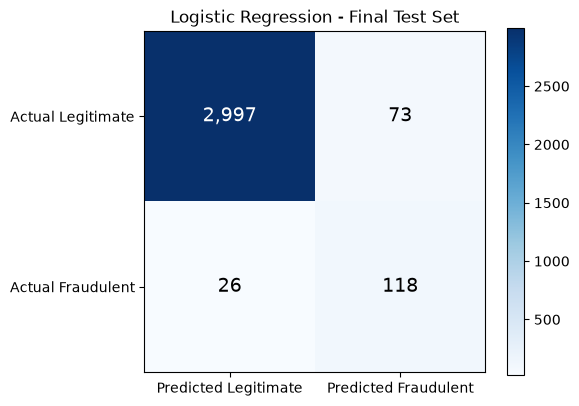

In [11]:
def evaluate_saved_pipeline(model_name, path, confusion_title, figure_name):
    pipeline = joblib.load(path)
    started = time.time()
    predictions = pipeline.predict(X_test)                          # raw text in, class out
    probabilities = pipeline.predict_proba(X_test)[:, 1]
    inference_seconds[model_name] = time.time() - started

    evaluated_on[model_name] = (hashlib.md5("\x00".join(X_test).encode()).hexdigest(), len(X_test))
    test_predictions[model_name] = np.asarray(predictions)
    test_fraud_probability[model_name] = np.asarray(probabilities)
    final_metrics[model_name] = calculate_metrics(y_test, predictions)

    metrics = final_metrics[model_name]
    print(f"{model_name} (FINAL TEST results)")
    print(f"  Accuracy:        {metrics['Accuracy']:.4f}")
    print(f"  Fraud precision: {metrics['Fraud Precision']:.4f}")
    print(f"  Fraud recall:    {metrics['Fraud Recall']:.4f}")
    print(f"  Fraud F1-score:  {metrics['Fraud F1']:.4f}")
    print(f"  TN {metrics['True Negatives']} | FP {metrics['False Positives']} | "
          f"FN {metrics['False Negatives']} | TP {metrics['True Positives']}")
    plot_confusion_matrix(y_test, predictions, confusion_title, FIGURES_DIR / figure_name)


evaluate_saved_pipeline("Logistic Regression", LR_PATH,
                        "Logistic Regression - Final Test Set", "final_logistic_confusion_matrix.png")

## 6. Evaluate Multinomial Naive Bayes

Same test rows, same metrics.

Multinomial Naive Bayes (FINAL TEST results)
  Accuracy:        0.9776
  Fraud precision: 0.8273
  Fraud recall:    0.6319
  Fraud F1-score:  0.7165
  TN 3051 | FP 19 | FN 53 | TP 91


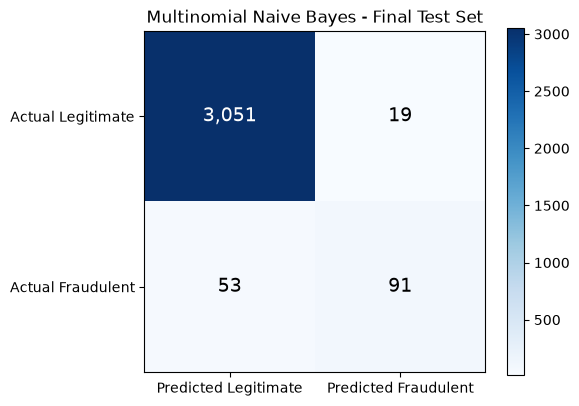

In [12]:
evaluate_saved_pipeline("Multinomial Naive Bayes", NB_PATH,
                        "Multinomial Naive Bayes - Final Test Set", "final_naive_bayes_confusion_matrix.png")

## 7. Evaluate XGBoost

Same test rows, same metrics.

XGBoost (FINAL TEST results)
  Accuracy:        0.9795
  Fraud precision: 0.8250
  Fraud recall:    0.6875
  Fraud F1-score:  0.7500
  TN 3049 | FP 21 | FN 45 | TP 99


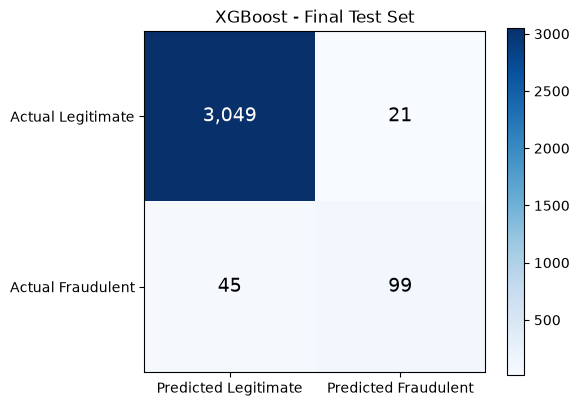

In [13]:
evaluate_saved_pipeline("XGBoost", XGB_PATH,
                        "XGBoost - Final Test Set", "final_xgboost_confusion_matrix.png")

## 8. Evaluate DistilBERT

We load the **saved full-train model and its tokenizer** from `models/distilbert/`. There is **no TF-IDF** and **no training here**: the model is only switched to evaluation mode and used for inference.

Each batch of raw `combined_text` is tokenized with `truncation=True`, `max_length=256` and padding up to the longest text in that batch, exactly as during fine-tuning. Predictions are made in batches; the predicted class is the more probable of the two outputs. We use the GPU (CUDA or Apple MPS) if available, otherwise the CPU.

In [14]:
if torch.cuda.is_available():
    device_name = "cuda"
elif torch.backends.mps.is_available():
    device_name = "mps"
else:
    device_name = "cpu"

distilbert_tokenizer = AutoTokenizer.from_pretrained(DISTILBERT_DIR)
distilbert_model = AutoModelForSequenceClassification.from_pretrained(DISTILBERT_DIR).to(device_name)
distilbert_model.eval()     # inference mode: dropout is switched off, no weights are updated

print("Loaded from:", DISTILBERT_DIR.relative_to(PROJECT_ROOT), "| device:", device_name)
print("Output classes:", distilbert_model.config.num_labels, "| tokenizer vocabulary:", len(distilbert_tokenizer))
assert distilbert_model.config.num_labels == 2 and not distilbert_model.training

W1021 21:16:09.585000 15395 .venv/lib/python3.14/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loaded from: models/distilbert | device: mps
Output classes: 2 | tokenizer vocabulary: 30522


In [15]:
MAX_LENGTH = 256
INFERENCE_BATCH_SIZE = 32


def predict_distilbert(texts):
    # Returns the predicted class and the fraud probability for every text, in the original order
    texts = list(texts)
    probabilities = []
    for start in range(0, len(texts), INFERENCE_BATCH_SIZE):
        batch = distilbert_tokenizer(texts[start:start + INFERENCE_BATCH_SIZE], truncation=True, max_length=MAX_LENGTH,
                                     padding=True, return_tensors="pt", return_token_type_ids=False).to(device_name)
        with torch.no_grad():
            logits = distilbert_model(**batch).logits
        probabilities.extend(torch.softmax(logits, dim=-1)[:, 1].cpu().tolist())
        if (start // INFERENCE_BATCH_SIZE) % 20 == 0:
            print(f"  ... {min(start + INFERENCE_BATCH_SIZE, len(texts)):,} / {len(texts):,} postings")
    probabilities = np.array(probabilities)
    return (probabilities > 0.5).astype(int), probabilities       # fraud if its probability is above 50%


started = time.time()
distilbert_pred, distilbert_prob = predict_distilbert(X_test)
inference_seconds["DistilBERT"] = time.time() - started
print(f"DistilBERT inference on {len(X_test):,} test postings took {inference_seconds['DistilBERT']:.1f} s on {device_name}")

evaluated_on["DistilBERT"] = (hashlib.md5("\x00".join(X_test).encode()).hexdigest(), len(X_test))
test_predictions["DistilBERT"] = distilbert_pred
test_fraud_probability["DistilBERT"] = distilbert_prob
final_metrics["DistilBERT"] = calculate_metrics(y_test, distilbert_pred)

  ... 32 / 3,214 postings


  ... 672 / 3,214 postings


  ... 1,312 / 3,214 postings


  ... 1,952 / 3,214 postings


  ... 2,592 / 3,214 postings


  ... 3,214 / 3,214 postings
DistilBERT inference on 3,214 test postings took 32.1 s on mps


DistilBERT (FINAL TEST results)
  Accuracy:        0.9841
  Fraud precision: 0.8843
  Fraud recall:    0.7431
  Fraud F1-score:  0.8075
  TN 3056 | FP 14 | FN 37 | TP 107


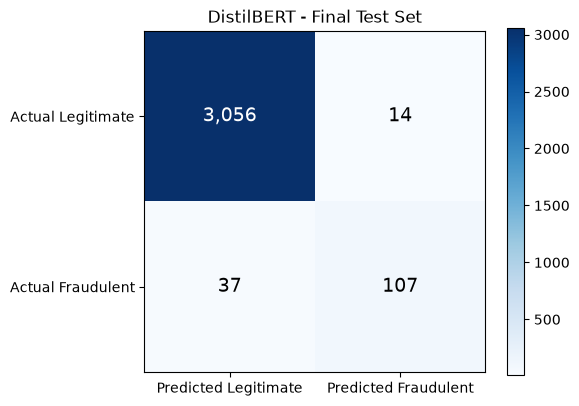

In [16]:
metrics = final_metrics["DistilBERT"]
print("DistilBERT (FINAL TEST results)")
print(f"  Accuracy:        {metrics['Accuracy']:.4f}")
print(f"  Fraud precision: {metrics['Fraud Precision']:.4f}")
print(f"  Fraud recall:    {metrics['Fraud Recall']:.4f}")
print(f"  Fraud F1-score:  {metrics['Fraud F1']:.4f}")
print(f"  TN {metrics['True Negatives']} | FP {metrics['False Positives']} | FN {metrics['False Negatives']} | TP {metrics['True Positives']}")
plot_confusion_matrix(y_test, distilbert_pred, "DistilBERT - Final Test Set",
                      FIGURES_DIR / "final_distilbert_confusion_matrix.png")

## 9. Final four-model table

All four models, on the same 3,214 test postings. Fraud is the positive class: a **false positive** is a legitimate posting wrongly flagged (a false alarm); a **false negative** is a scam that slipped through (a missed scam).

In [17]:
model_order = ["Logistic Regression", "Multinomial Naive Bayes", "XGBoost", "DistilBERT"]
table_columns = ["Model", "Accuracy", "Fraud Precision", "Fraud Recall", "Fraud F1",
                 "False Positives", "False Negatives", "True Positives", "True Negatives"]

final_table = pd.DataFrame([{"Model": name, **final_metrics[name]} for name in model_order])[table_columns]
final_table.to_csv(METRICS_DIR / "final_test_model_comparison.csv", index=False)
print("Saved results/metrics/final_test_model_comparison.csv")

# Sorted by fraud F1 for display only; the saved file keeps the original order
final_table.sort_values("Fraud F1", ascending=False).round(4).reset_index(drop=True)

Saved results/metrics/final_test_model_comparison.csv


,Model,Accuracy,Fraud Precision,Fraud Recall,Fraud F1,False Positives,False Negatives,True Positives,True Negatives
0,DistilBERT,0.9841,0.8843,0.7431,0.8075,14,37,107,3056
1,XGBoost,0.9795,0.8250,0.6875,0.7500,21,45,99,3049
2,Multinomial Naive Bayes,0.9776,0.8273,0.6319,0.7165,19,53,91,3051
3,Logistic Regression,0.9692,0.6178,0.8194,0.7045,73,26,118,2997


## 10. Final comparison chart

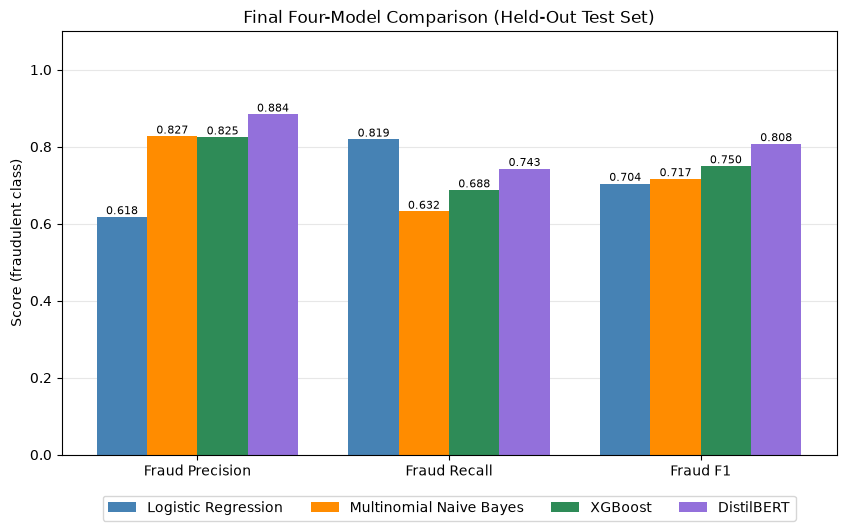

In [18]:
chart_metrics = ["Fraud Precision", "Fraud Recall", "Fraud F1"]
bar_colors = ["steelblue", "darkorange", "seagreen", "mediumpurple"]
positions = np.arange(len(chart_metrics))
bar_width = 0.2

fig, ax = plt.subplots(figsize=(10, 5.5))
for index, (_, row) in enumerate(final_table.iterrows()):
    bars = ax.bar(positions + (index - 1.5) * bar_width, row[chart_metrics].astype(float),
                  bar_width, label=row["Model"], color=bar_colors[index])
    ax.bar_label(bars, fmt="%.3f", fontsize=8)

ax.set_xticks(positions, labels=chart_metrics)
ax.set_ylim(0, 1.1)
ax.set_ylabel("Score (fraudulent class)")
ax.set_title("Final Four-Model Comparison (Held-Out Test Set)")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=4)
fig.savefig(FIGURES_DIR / "final_four_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. The four confusion matrices

The individual matrices were saved in Sections 5-8:
`final_logistic_confusion_matrix.png`, `final_naive_bayes_confusion_matrix.png`, `final_xgboost_confusion_matrix.png`, `final_distilbert_confusion_matrix.png`. Below they are shown together side by side (this overview is also saved, for slides).

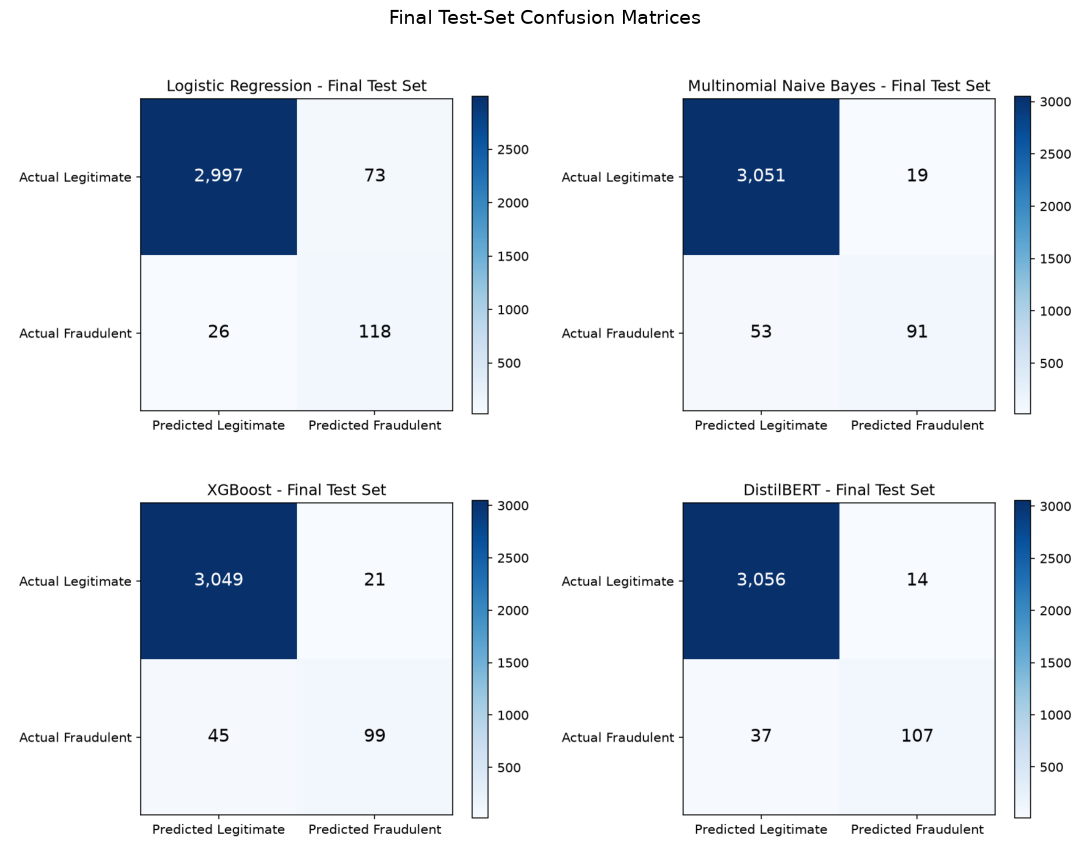

In [19]:
confusion_files = ["final_logistic_confusion_matrix.png", "final_naive_bayes_confusion_matrix.png",
                   "final_xgboost_confusion_matrix.png", "final_distilbert_confusion_matrix.png"]
for file_name in confusion_files:
    assert (FIGURES_DIR / file_name).stat().st_size > 0

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, file_name in zip(axes.ravel(), confusion_files):
    ax.imshow(plt.imread(FIGURES_DIR / file_name))
    ax.axis("off")
fig.suptitle("Final Test-Set Confusion Matrices", fontsize=14)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "final_four_confusion_matrices_overview.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. Choose the final JobGuard model

We apply the selection rule declared in Section 3. First we measure how much of each F1 difference could be noise, using a **paired bootstrap**: the test postings are resampled with replacement (2,000 times, fixed seed), and every model's F1 is recomputed on the *same* resample. This only describes uncertainty; it does not change any model.

In [20]:
rng = np.random.default_rng(42)
N_BOOTSTRAP = 2000
y_true = y_test.to_numpy()
resample = rng.integers(0, len(y_true), size=(N_BOOTSTRAP, len(y_true)))


def bootstrap_f1(predictions):
    truth = y_true[resample]
    predicted = np.asarray(predictions)[resample]
    tp = (truth * predicted).sum(axis=1)
    fp = ((1 - truth) * predicted).sum(axis=1)
    fn = (truth * (1 - predicted)).sum(axis=1)
    return np.where(2 * tp + fp + fn > 0, 2 * tp / np.maximum(2 * tp + fp + fn, 1), 0.0)


bootstrap_scores = {name: bootstrap_f1(test_predictions[name]) for name in model_order}

interval_rows = []
for name in model_order:
    low, high = np.percentile(bootstrap_scores[name], [2.5, 97.5])
    interval_rows.append({"Model": name, "Fraud F1": final_metrics[name]["Fraud F1"],
                          "F1 95% interval (low)": low, "F1 95% interval (high)": high})
f1_intervals = pd.DataFrame(interval_rows)
f1_intervals.round(3)

,Model,Fraud F1,F1 95% interval (low),F1 95% interval (high)
0,Logistic Regression,0.704,0.645,0.760
1,Multinomial Naive Bayes,0.717,0.648,0.777
2,XGBoost,0.750,0.690,0.805
3,DistilBERT,0.808,0.753,0.859


In [21]:
LIGHTWEIGHT_MODELS = ["Logistic Regression", "Multinomial Naive Bayes", "XGBoost"]

leader = final_table.loc[final_table["Fraud F1"].idxmax(), "Model"]
leader_f1 = final_metrics[leader]["Fraud F1"]

comparison_rows = []
for name in model_order:
    if name == leader:
        continue
    difference = bootstrap_scores[leader] - bootstrap_scores[name]
    low, high = np.percentile(difference, [2.5, 97.5])
    comparison_rows.append({"Leader": leader, "Compared with": name,
                            "F1 difference": leader_f1 - final_metrics[name]["Fraud F1"],
                            "95% interval (low)": low, "95% interval (high)": high,
                            "Essentially tied": bool(low <= 0 <= high)})
leader_comparison = pd.DataFrame(comparison_rows)
print(f"Leader by test fraud F1: {leader} (F1 {leader_f1:.4f})\n")
print(leader_comparison.round(4).to_string(index=False))

Leader by test fraud F1: DistilBERT (F1 0.8075)

    Leader           Compared with  F1 difference  95% interval (low)  95% interval (high)  Essentially tied
DistilBERT     Logistic Regression         0.1031              0.0514               0.1582             False
DistilBERT Multinomial Naive Bayes         0.0910              0.0348               0.1513             False
DistilBERT                 XGBoost         0.0575              0.0085               0.1115             False


In [22]:
# --- Apply the pre-declared rule from Section 3 ---
tied_models = leader_comparison.loc[leader_comparison["Essentially tied"], "Compared with"].tolist()
tied_lightweight = [name for name in tied_models if name in LIGHTWEIGHT_MODELS]

if leader == "DistilBERT" and tied_lightweight:
    final_model_name = max(tied_lightweight, key=lambda name: final_metrics[name]["Fraud F1"])
    rule_note = "tie rule applied"
else:
    final_model_name = leader
    rule_note = "leader selected"

selected = final_metrics[final_model_name]
highest_accuracy_model = final_table.loc[final_table["Accuracy"].idxmax(), "Model"]

print("FINAL JOBGUARD MODEL:", final_model_name, f"({rule_note})")
print(f"  test fraud F1 {selected['Fraud F1']:.4f} | precision {selected['Fraud Precision']:.4f} | "
      f"recall {selected['Fraud Recall']:.4f} | accuracy {selected['Accuracy']:.4f}")
print(f"  missed scams (FN): {selected['False Negatives']} of {n_test_fraud} | false alarms (FP): {selected['False Positives']} of {n_test_legit}")
print("Models essentially tied with the F1 leader:", tied_models or "none")
print("Highest-accuracy model (NOT used for the decision):", highest_accuracy_model)

# --- A rationale built from the numbers above ---
rationale = (f"Test fraud F1 {selected['Fraud F1']:.3f} (precision {selected['Fraud Precision']:.3f}, "
             f"recall {selected['Fraud Recall']:.3f}); {selected['False Negatives']} of {n_test_fraud} scams missed and "
             f"{selected['False Positives']} false alarms among {n_test_legit:,} legitimate postings. ")
if rule_note == "tie rule applied":
    tie_row = leader_comparison[leader_comparison["Compared with"] == final_model_name].iloc[0]
    rationale += (f"DistilBERT had the highest F1 ({leader_f1:.3f}), but the 95% bootstrap interval of its F1 advantage "
                  f"({tie_row['95% interval (low)']:+.3f} to {tie_row['95% interval (high)']:+.3f}) includes 0, so the two are "
                  f"essentially tied; the lighter model was chosen for deployment simplicity, as declared before testing.")
else:
    rationale += f"Highest fraud F1 of the four models. "
    if tied_models:
        rationale += f"Within bootstrap noise of it: {', '.join(tied_models)}. "
    else:
        rationale += "Its F1 advantage over every other model is outside bootstrap noise. "
    if highest_accuracy_model != final_model_name:
        rationale += f"({highest_accuracy_model} has the highest accuracy, which was not used because most postings are legitimate.)"
print()
print("Rationale:", rationale)

FINAL JOBGUARD MODEL: DistilBERT (leader selected)
  test fraud F1 0.8075 | precision 0.8843 | recall 0.7431 | accuracy 0.9841
  missed scams (FN): 37 of 144 | false alarms (FP): 14 of 3070
Models essentially tied with the F1 leader: none
Highest-accuracy model (NOT used for the decision): DistilBERT

Rationale: Test fraud F1 0.808 (precision 0.884, recall 0.743); 37 of 144 scams missed and 14 false alarms among 3,070 legitimate postings. Highest fraud F1 of the four models. Its F1 advantage over every other model is outside bootstrap noise. 


**The trade-off in the final test results** (fraud is the positive class; 144 fraudulent and 3,070 legitimate test postings):

- **DistilBERT** has the highest fraud F1 (0.808), the highest precision (0.884) and the fewest false alarms (14), with the second-highest recall (0.743). It still misses 37 of 144 scams.
- **Logistic Regression** has the highest recall (0.819, only 26 missed scams) but pays with 73 false alarms (precision 0.618), so its F1 (0.704) is the lowest.
- **Naive Bayes** and **XGBoost** sit in between: few false alarms (19 and 21), but more missed scams (53 and 45); XGBoost is the stronger of the two (F1 0.750 versus 0.717).

**How decisive is DistilBERT's lead?** Its F1 advantage over every other model is outside the bootstrap noise (no model is essentially tied with it). The margin over XGBoost, the runner-up, is the smallest: its 95% interval runs from +0.009 to +0.112, so the lower end is close to zero. The ranking is clear, but with only 144 fraudulent test postings the exact size of the gap is uncertain.

By the pre-declared rule, **DistilBERT** is the final JobGuard model. It is also the most accurate model, but accuracy was not used for the decision. This choice is final: nothing is tuned further based on these test results.

## 13. Practical deployment consideration

Besides accuracy of the predictions, the web app has to run the model. The table below uses **measured** values from this run: the size of each saved model, and how long each model took to predict all 3,214 test postings on this machine (for the three TF-IDF pipelines this includes the TF-IDF step). Timings depend on the hardware and are only indicative.

In [23]:
def folder_size_mb(folder):
    return sum(path.stat().st_size for path in Path(folder).rglob("*") if path.is_file()) / 1024 ** 2


deployment = pd.DataFrame([
    {"Model": "Logistic Regression", "Saved size (MB)": LR_PATH.stat().st_size / 1024 ** 2, "Software needed": "scikit-learn"},
    {"Model": "Multinomial Naive Bayes", "Saved size (MB)": NB_PATH.stat().st_size / 1024 ** 2, "Software needed": "scikit-learn"},
    {"Model": "XGBoost", "Saved size (MB)": XGB_PATH.stat().st_size / 1024 ** 2, "Software needed": "scikit-learn + xgboost"},
    {"Model": "DistilBERT", "Saved size (MB)": folder_size_mb(DISTILBERT_DIR), "Software needed": "PyTorch + transformers"},
])
deployment["Test inference (s)"] = [inference_seconds[name] for name in deployment["Model"]]
deployment["ms per posting"] = deployment["Test inference (s)"] / len(X_test) * 1000
deployment["Inference hardware"] = ["CPU"] * 3 + [device_name]
deployment.to_csv(METRICS_DIR / "final_deployment_comparison.csv", index=False)
deployment.round(2)

,Model,Saved size (MB),Software needed,Test inference (s),ms per posting,Inference hardware
0,Logistic Regression,0.97,scikit-learn,0.84,0.26,CPU
1,Multinomial Naive Bayes,1.42,scikit-learn,0.85,0.26,CPU
2,XGBoost,1.09,scikit-learn + xgboost,0.86,0.27,CPU
3,DistilBERT,256.10,PyTorch + transformers,32.10,9.99,mps


**What the numbers say.** The three TF-IDF models are only about 1.0-1.4 MB each and score a posting in roughly 0.27 ms on a CPU. DistilBERT is about 256 MB, needs PyTorch and transformers, and took about 10 ms per posting here, using the mps GPU in batches of 32. Its CPU-only speed was **not measured**.

**What it means for the decision.** DistilBERT is clearly the stronger model on the final test, so it is **not** overridden for being heavier. For a demo app that checks one posting at a time, a delay of that order is acceptable, but the web app will need PyTorch and a larger download, and a CPU-only host may be slower than measured here. XGBoost (F1 0.750) remains available in `src/final_model_config.json` as the lightweight fallback should deployment limits require it.

## 14. Save the final decision

Two files are written: a table for the report (`results/metrics/final_model_decision.csv`) and a small configuration file (`src/final_model_config.json`) that tells the future backend which model to load. The other models are **not** deleted.

In [24]:
decision = pd.DataFrame([{
    "Selected Model": final_model_name,
    "Test Accuracy": selected["Accuracy"],
    "Fraud Precision": selected["Fraud Precision"],
    "Fraud Recall": selected["Fraud Recall"],
    "Fraud F1": selected["Fraud F1"],
    "False Positives": selected["False Positives"],
    "False Negatives": selected["False Negatives"],
    "Rationale": rationale,
}])
decision.to_csv(METRICS_DIR / "final_model_decision.csv", index=False)

artifact_for = {
    "Logistic Regression": ("sklearn_pipeline", "models/logistic_regression_pipeline.joblib"),
    "Multinomial Naive Bayes": ("sklearn_pipeline", "models/naive_bayes_pipeline.joblib"),
    "XGBoost": ("sklearn_pipeline", "models/xgboost_pipeline.joblib"),
    "DistilBERT": ("transformers_folder", "models/distilbert/"),
}
artifact_type, artifact_path = artifact_for[final_model_name]

model_config = {
    "selected_model": final_model_name,
    "artifact_type": artifact_type,
    "artifact_path": artifact_path,
    "input": "raw combined_text string (TITLE / COMPANY PROFILE / DESCRIPTION / REQUIREMENTS / BENEFITS)",
    "prediction_rule": "predicted class (default 0.5 probability threshold); fraud probability = probability of class 1",
    "distilbert_max_length": 256,
    "test_metrics": {"accuracy": round(float(selected["Accuracy"]), 4),
                     "fraud_precision": round(float(selected["Fraud Precision"]), 4),
                     "fraud_recall": round(float(selected["Fraud Recall"]), 4),
                     "fraud_f1": round(float(selected["Fraud F1"]), 4)},
    "all_model_artifacts": {name: path for name, (_, path) in artifact_for.items()},
    "note": "Generated by notebooks/07_final_model_evaluation.ipynb. Configuration locked before test evaluation.",
}
CONFIG_PATH = PROJECT_ROOT / "src" / "final_model_config.json"
CONFIG_PATH.write_text(json.dumps(model_config, indent=2) + "\n")
print("Saved results/metrics/final_model_decision.csv and", CONFIG_PATH.relative_to(PROJECT_ROOT))
print(json.dumps(model_config, indent=2))

Saved results/metrics/final_model_decision.csv and src/final_model_config.json
{
  "selected_model": "DistilBERT",
  "artifact_type": "transformers_folder",
  "artifact_path": "models/distilbert/",
  "input": "raw combined_text string (TITLE / COMPANY PROFILE / DESCRIPTION / REQUIREMENTS / BENEFITS)",
  "prediction_rule": "predicted class (default 0.5 probability threshold); fraud probability = probability of class 1",
  "distilbert_max_length": 256,
  "test_metrics": {
    "accuracy": 0.9841,
    "fraud_precision": 0.8843,
    "fraud_recall": 0.7431,
    "fraud_f1": 0.8075
  },
  "all_model_artifacts": {
    "Logistic Regression": "models/logistic_regression_pipeline.joblib",
    "Multinomial Naive Bayes": "models/naive_bayes_pipeline.joblib",
    "XGBoost": "models/xgboost_pipeline.joblib",
    "DistilBERT": "models/distilbert/"
  },
  "note": "Generated by notebooks/07_final_model_evaluation.ipynb. Configuration locked before test evaluation."
}


## 15. Presentation material

### Validation versus final test
- **Validation** results (Milestones 5-7) were used to **choose settings** inside `train.csv`. Those models were trained on 80% of `train.csv` and scored on the other 20%.
- **Final test** results above come from the **locked full-train models** scored once on `test.csv`, which was never used for any decision about a model's settings. The test set gives the honest estimate of how each model behaves on new postings. (The final selection among the four finished models is the only decision it informs.)

The table and chart below put the two side by side, **read from the saved metric files** (not typed in).

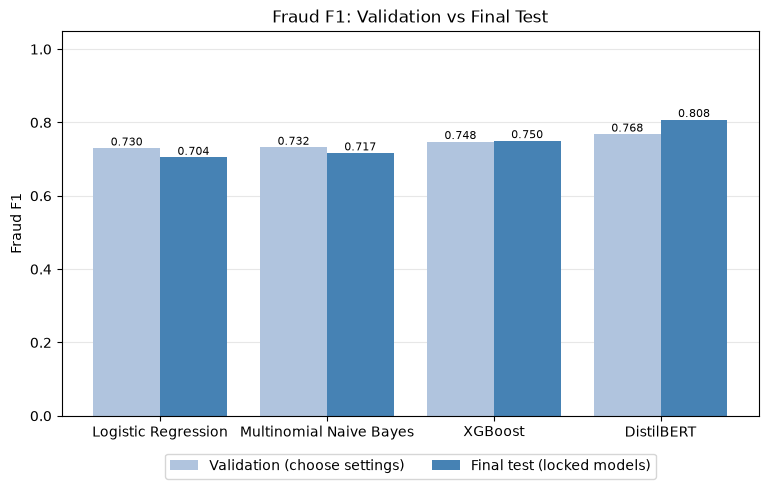

,Model,Validation Fraud F1,Final Test Fraud F1,Difference (test - validation)
0,Logistic Regression,0.7298,0.7045,-0.0253
1,Multinomial Naive Bayes,0.7320,0.7165,-0.0154
2,XGBoost,0.7476,0.7500,0.0024
3,DistilBERT,0.7678,0.8075,0.0398


In [25]:
saved_nb_xgb = pd.read_csv(METRICS_DIR / "model_validation_comparison.csv")
saved_distilbert_validation = pd.read_csv(METRICS_DIR / "distilbert_validation_results.csv")

validation_f1 = {
    "Logistic Regression": float(lr_validation.loc[lr_validation["Model"] == selected_lr_name, "Fraud F1"].iloc[0]),
    "Multinomial Naive Bayes": float(saved_nb_xgb.loc[saved_nb_xgb["Model"] == "Multinomial Naive Bayes", "Fraud F1"].iloc[0]),
    "XGBoost": float(saved_nb_xgb.loc[saved_nb_xgb["Model"] == "XGBoost", "Fraud F1"].iloc[0]),
    "DistilBERT": float(saved_distilbert_validation.loc[saved_distilbert_validation["Model"] == "DistilBERT", "Fraud F1"].iloc[0]),
}
validation_vs_test = pd.DataFrame([{"Model": name,
                                    "Validation Fraud F1": validation_f1[name],
                                    "Final Test Fraud F1": final_metrics[name]["Fraud F1"],
                                    "Difference (test - validation)": final_metrics[name]["Fraud F1"] - validation_f1[name]}
                                   for name in model_order])
validation_vs_test.to_csv(METRICS_DIR / "validation_vs_test_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
positions = np.arange(len(model_order))
bars_validation = ax.bar(positions - 0.2, validation_vs_test["Validation Fraud F1"], 0.4, label="Validation (choose settings)", color="lightsteelblue")
bars_test = ax.bar(positions + 0.2, validation_vs_test["Final Test Fraud F1"], 0.4, label="Final test (locked models)", color="steelblue")
ax.bar_label(bars_validation, fmt="%.3f", fontsize=8)
ax.bar_label(bars_test, fmt="%.3f", fontsize=8)
ax.set_xticks(positions, labels=model_order)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Fraud F1")
ax.set_title("Fraud F1: Validation vs Final Test")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2)
fig.savefig(FIGURES_DIR / "validation_vs_test_fraud_f1.png", dpi=150, bbox_inches="tight")
plt.show()

validation_vs_test.round(4)

### Precision versus recall, in plain words
- **Precision:** of the postings the model flags as fraudulent, how many really are. Low precision means many **false alarms**, which hurts honest employers and annoys users.
- **Recall:** of all the real scams, how many the model catches. Low recall means **missed scams**, which is the harm the product exists to prevent.
- **F1** is a single summary that is high only when both are reasonably high. Accuracy is not used to choose, because about 95% of postings are legitimate: a model that never flags anything already scores about 95%.

Models sit at different points on this trade-off: some catch more scams at the price of more false alarms, others raise fewer false alarms but miss more scams. Which point is best depends on the product; the confusion matrices and the false-positive / false-negative counts make the trade visible.

### Methodology caveat (for the report)
- Naive Bayes, XGBoost and DistilBERT were selected on **validation data only**.
- Logistic Regression was evaluated on `test.csv` **once, early** (Milestone 4), before the validation protocol existed. For this final comparison its configuration was **re-selected from validation only** (Section 2) and retrained, so the final choice does not depend on that early result. The holdout was nevertheless inspected during that early experiment; this should be disclosed in the report.
- **No tuning was performed after the final test evaluation**: all configurations were locked and fingerprinted before `test.csv` was loaded, and Section 16 verifies that nothing changed.

## 16. Validation checks

Each `assert` stops the notebook with an error if a check fails.

In [26]:
# Also keep the per-posting predictions (no text) so later analysis does not need to re-run the models
predictions_table = pd.DataFrame({"row": np.arange(len(y_test)), "actual": y_test.to_numpy()})
for name in model_order:
    predictions_table[f"{name} predicted"] = test_predictions[name]
    predictions_table[f"{name} fraud probability"] = test_fraud_probability[name]
predictions_table.to_csv(METRICS_DIR / "final_test_predictions.csv", index=False)

# 1. All four models evaluated the identical test rows
assert set(evaluated_on) == set(model_order)
assert all(fingerprint == test_text_fingerprint and rows == len(X_test) == 3214 for fingerprint, rows in evaluated_on.values())
assert all(len(test_predictions[name]) == len(y_test) for name in model_order)
print("PASS: all four models were evaluated on the identical 3,214 test rows (same text fingerprint)")

# 2. test.csv and train.csv were not modified
data_fingerprints_at_end = {"train.csv": file_fingerprint(TRAIN_PATH), "test.csv": file_fingerprint(TEST_PATH)}
assert data_fingerprints_at_end == data_fingerprints_at_start
print("PASS: train.csv and test.csv are unchanged (identical fingerprints at start and end)")

# 3. No training on test.csv: the TF-IDF vocabulary of every saved pipeline equals one learned from train.csv alone
vocabulary_from_train_only = list(TfidfVectorizer(**tfidf_settings).fit(X_all).get_feature_names_out())
for name, path in [("Logistic Regression", LR_PATH), ("Multinomial Naive Bayes", NB_PATH), ("XGBoost", XGB_PATH)]:
    pipeline_vocabulary = list(joblib.load(path).named_steps["tfidf"].get_feature_names_out())
    assert pipeline_vocabulary == vocabulary_from_train_only
print("PASS: no test text entered any model (TF-IDF vocabularies equal those learned from train.csv alone)")

# 4. No model file or setting changed after the lock (so nothing was tuned after seeing test results)
fingerprints_after = {"Logistic Regression": file_fingerprint(LR_PATH), "Multinomial Naive Bayes": file_fingerprint(NB_PATH),
                      "XGBoost": file_fingerprint(XGB_PATH), "DistilBERT": distilbert_fingerprint()}
assert fingerprints_after == lock_fingerprints
settings_after = {"Logistic Regression": settings_fingerprint(joblib.load(LR_PATH)),
                  "Multinomial Naive Bayes": settings_fingerprint(joblib.load(NB_PATH)),
                  "XGBoost": settings_fingerprint(joblib.load(XGB_PATH))}
assert settings_after == lock_settings
print("PASS: all four model files and all hyperparameters are identical to the values locked before testing")

# 5. No threshold was changed: every prediction is exactly the default 0.5 rule applied to the stored probabilities
for name in model_order:
    assert ((test_fraud_probability[name] > 0.5).astype(int) == test_predictions[name]).all()
print("PASS: every model's predictions equal the default 0.5 probability rule (no threshold tuning)")

# 6. DistilBERT inference used the saved full-train model
assert str(DISTILBERT_DIR) in str(distilbert_model.name_or_path) and not distilbert_model.training
assert int(run_info["final_model_trained_on_rows"]) == len(X_all) and run_info["test_csv_used"] == "no"
print("PASS: DistilBERT predictions came from models/distilbert/ (full-train model, unchanged, inference mode)")

# 7. Metrics files exactly match the notebook results
metric_columns = ["Accuracy", "Fraud Precision", "Fraud Recall", "Fraud F1", "False Positives", "False Negatives",
                  "True Positives", "True Negatives"]
saved_table = pd.read_csv(METRICS_DIR / "final_test_model_comparison.csv")
assert list(saved_table["Model"]) == model_order
assert np.allclose(saved_table[metric_columns].to_numpy(dtype=float), final_table[metric_columns].to_numpy(dtype=float))
for name in model_order:     # confusion counts add up to the test size
    assert sum(final_metrics[name][k] for k in ["True Negatives", "False Positives", "False Negatives", "True Positives"]) == len(y_test)
saved_decision = pd.read_csv(METRICS_DIR / "final_model_decision.csv").iloc[0]
assert saved_decision["Selected Model"] == final_model_name
assert np.isclose(saved_decision["Fraud F1"], final_metrics[final_model_name]["Fraud F1"])
assert json.loads(CONFIG_PATH.read_text())["selected_model"] == final_model_name
print("PASS: the saved metrics files and the decision/config files exactly match the notebook results")

# 8. Figures exist and are non-empty
figure_files = ["final_four_model_comparison.png", "final_logistic_confusion_matrix.png",
                "final_naive_bayes_confusion_matrix.png", "final_xgboost_confusion_matrix.png",
                "final_distilbert_confusion_matrix.png", "final_four_confusion_matrices_overview.png",
                "validation_vs_test_fraud_f1.png"]
for file_name in figure_files:
    assert (FIGURES_DIR / file_name).stat().st_size > 0
print("PASS: all", len(figure_files), "figure files were saved and are non-empty")

# 9. The other models were not deleted
assert all(path.exists() for path in (LR_PATH, NB_PATH, XGB_PATH, DISTILBERT_DIR / "model.safetensors"))
print("PASS: all four models are still available")

PASS: all four models were evaluated on the identical 3,214 test rows (same text fingerprint)
PASS: train.csv and test.csv are unchanged (identical fingerprints at start and end)


PASS: no test text entered any model (TF-IDF vocabularies equal those learned from train.csv alone)


PASS: all four model files and all hyperparameters are identical to the values locked before testing
PASS: every model's predictions equal the default 0.5 probability rule (no threshold tuning)
PASS: DistilBERT predictions came from models/distilbert/ (full-train model, unchanged, inference mode)
PASS: the saved metrics files and the decision/config files exactly match the notebook results
PASS: all 7 figure files were saved and are non-empty
PASS: all four models are still available


## 17. Summary (numbers printed by code)

In [27]:
print("TEST SET:", f"{n_test:,} rows | legitimate {n_test_legit:,} | fraudulent {n_test_fraud:,} ({n_test_fraud / n_test * 100:.2f}%)")
print()
print(final_table.round(4).to_string(index=False))
print()
print("FINAL MODEL:", final_model_name)
print("Logistic Regression validation selection:", selected_lr_name)
print("DistilBERT inference device:", device_name, f"({inference_seconds['DistilBERT']:.1f} s for {n_test:,} postings)")
print("Files written to results/metrics:", sorted(p.name for p in METRICS_DIR.glob("final_*")) +
      ["logistic_regression_validation_selection.csv", "validation_vs_test_comparison.csv"])

TEST SET: 3,214 rows | legitimate 3,070 | fraudulent 144 (4.48%)

                  Model  Accuracy  Fraud Precision  Fraud Recall  Fraud F1  False Positives  False Negatives  True Positives  True Negatives
    Logistic Regression    0.9692           0.6178        0.8194    0.7045               73               26             118            2997
Multinomial Naive Bayes    0.9776           0.8273        0.6319    0.7165               19               53              91            3051
                XGBoost    0.9795           0.8250        0.6875    0.7500               21               45              99            3049
             DistilBERT    0.9841           0.8843        0.7431    0.8075               14               37             107            3056

FINAL MODEL: DistilBERT
Logistic Regression validation selection: Logistic Regression (Balanced)
DistilBERT inference device: mps (32.1 s for 3,214 postings)
Files written to results/metrics: ['final_deployment_comparison.csv', 

## What we learned

- **Accuracy hides the real story.** All four models score between 0.969 and 0.984 accuracy, yet their fraud F1 ranges from 0.704 to 0.808. Because about 95% of postings are legitimate, precision, recall and the confusion matrix are what distinguish the models.
- **The fine-tuned transformer worked best here.** DistilBERT, which reads postings as sequences in context, beat the three TF-IDF models, which only count words and phrases. Among the TF-IDF models, the non-linear XGBoost was best.
- **There is always a precision/recall trade-off.** Logistic Regression catches the most scams but raises the most false alarms; Naive Bayes and XGBoost are more cautious. DistilBERT achieved the best balance rather than winning on both extremes.
- **Validation was a reliable guide.** The models rank in the same order on validation and on the final test (DistilBERT, XGBoost, Multinomial Naive Bayes, Logistic Regression), which supports the validation-only selection protocol.
- **Honest caveats.** Only 144 fraudulent postings are in the test set, so small differences are uncertain (see the bootstrap intervals). `max_length=256` cuts off the end of most postings for DistilBERT. DistilBERT was trained once (single seed) on a GPU in Colab. EMSCAD is a single, older dataset, so these scores do not guarantee the same performance on new kinds of scams. Even the best model misses about 26% of the scams in the test set, so the app must present its output as a **warning signal, not a verdict**.